In [1]:
""""
Copyright (C) 2025 ETH Zurich, Stefan J.P. Chrin, Gregory Landrum, Sereina Riniker
"""

import sys
sys.path.append("../../../SRC/")

### Define Parameters and preprocess the data

In [2]:
import sys 

from DDG_ANALYSIS.B_PREPROCESS import preprocess

# --- Dictionary mapping file names to their json file paths ---
files = {
    "RFR 2D": "../../../A_MODELS/2D/STRAT/A_RF_MORGAN_COUNT/dG_pred_&_error_all_splits.json",
    "RFR 3D": "../../../A_MODELS/3D/STRAT/A_RF_3D_DESCRIPTORS/dG_pred_&_error_all_splits.json",
    "Pycomsia": "../../../A_MODELS/PYC/STRAT/B_FORMAT_PREDICTIONS/dG_pred_&_error_all_splits.json",
    "Pycomsia (MIF)": "../../../A_MODELS/MIF/STRAT/B_FORMAT_PREDICTIONS/dG_pred_&_error_all_splits.json",
    "Meta-learner": "../../../A_MODELS/Z_META/DG/STRAT/dG_ridge_LOO_pred&error.json",
    "FEP (OFF)": "../../../A_MODELS/FEP/DG/OFF/OFF_STRAT_dG_pred&error.json",
    "FEP (OPLS3e)": "../../../A_MODELS/FEP/DG/OPLS/OPLS_STRAT_dG_pred&error.json"
}


DISPLAY_ORDER = ["FEP (OPLS3e)","FEP (OFF)", "Meta-learner" ,"Pycomsia (MIF)", "Pycomsia" ,"RFR 3D", "RFR 2D"]
DISPLAY_ORDER.reverse()
ALPHA = 0.01
TARGETS_TO_SKIP = ("galectin","p2","thrombin","cdk8","hif2a","hunt", "jnk1", "eg5") # jnk1 and eg5 have no molecules of class 0 in their test set because range is to small
METRICS = ["rmse", "kendalls_tau", "window_tau", "slope_diff", "mcc"]

target_counts = "../../../0_DATA/N_COMPOUNDS_PER_TARGET.json"

results_all, bad_splits = preprocess(files, TARGETS_TO_SKIP,MCC=True)

/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/SRC/DDG_ANALYSIS/A_W_TAU.py:63: RuntimeWarning: invalid value encountered in scalar divide
  tau = (nconcord - ndiscord) / np.sqrt((nconcord + ndiscord + ntx)*(nconcord + ndiscord + nty))


Window tau NaN: method=RFR 3D, target=cdk2, split=51  (NaN is generally due to constant (or in the case of window tau, verry simmilar) values in one of the two input arrays)


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/SRC/DDG_ANALYSIS/A_W_TAU.py:63: RuntimeWarning: invalid value encountered in scalar divide
  tau = (nconcord - ndiscord) / np.sqrt((nconcord + ndiscord + ntx)*(nconcord + ndiscord + nty))


Window tau NaN: method=Pycomsia (MIF), target=p38, split=19  (NaN is generally due to constant (or in the case of window tau, verry simmilar) values in one of the two input arrays)



Removed split summary:
  cdk2: 1 splits removed → [51]
  p38: 1 splits removed → [19]


In [3]:
# Check which splits have constant labels or predictions
print(bad_splits)

{'cdk2': {51}, 'p38': {19}}


### Friedman ANOVA

In [4]:
from DDG_ANALYSIS.C_FRIEDMAN_ANOVA import run_friedman

friedman_results = run_friedman(results_all, METRICS, TARGETS_TO_SKIP=TARGETS_TO_SKIP)
print(friedman_results)

{'rmse': {'bace': {'statistic': 304.1528571428571, 'p_value': 1.0540262430359001e-62}, 'cdk2': {'statistic': 390.3073593073591, 'p_value': 3.3885040869631437e-81}, 'cmet': {'statistic': 303.76714285714297, 'p_value': 1.2750090295560473e-62}, 'mcl1': {'statistic': 430.1185714285716, 'p_value': 9.312453383973249e-90}, 'p38': {'statistic': 212.50649350649337, 'p_value': 4.117464878659981e-43}, 'pde10': {'statistic': 466.08428571428567, 'p_value': 1.6929704223779584e-97}, 'pde2': {'statistic': 440.6057142857144, 'p_value': 5.159857515404393e-92}, 'pfkfb3': {'statistic': 213.09000000000015, 'p_value': 3.092305733022189e-43}, 'ptp1b': {'statistic': 188.0271428571432, 'p_value': 6.683656160675323e-38}, 'ros1': {'statistic': 131.93142857142857, 'p_value': 5.037628543721736e-26}, 'shp2': {'statistic': 310.9328571428573, 'p_value': 3.7120860330299495e-64}, 'syk': {'statistic': 504.2828571428572, 'p_value': 1.0047826958750094e-105}, 'tnks2': {'statistic': 335.8114285714287, 'p_value': 1.712965900

### Wilcoxon test

In [5]:
from DDG_ANALYSIS.D_WILCOXON import compute_wilcox_posthoc
wilcox_posthoc_results = compute_wilcox_posthoc(results_all, metrics=METRICS, targets_to_skip=TARGETS_TO_SKIP)


Identical MCC values: bace → RFR 2D vs RFR 3D
Identical MCC values: shp2 → Pycomsia vs Pycomsia (MIF)


### Significance plot

rmse significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


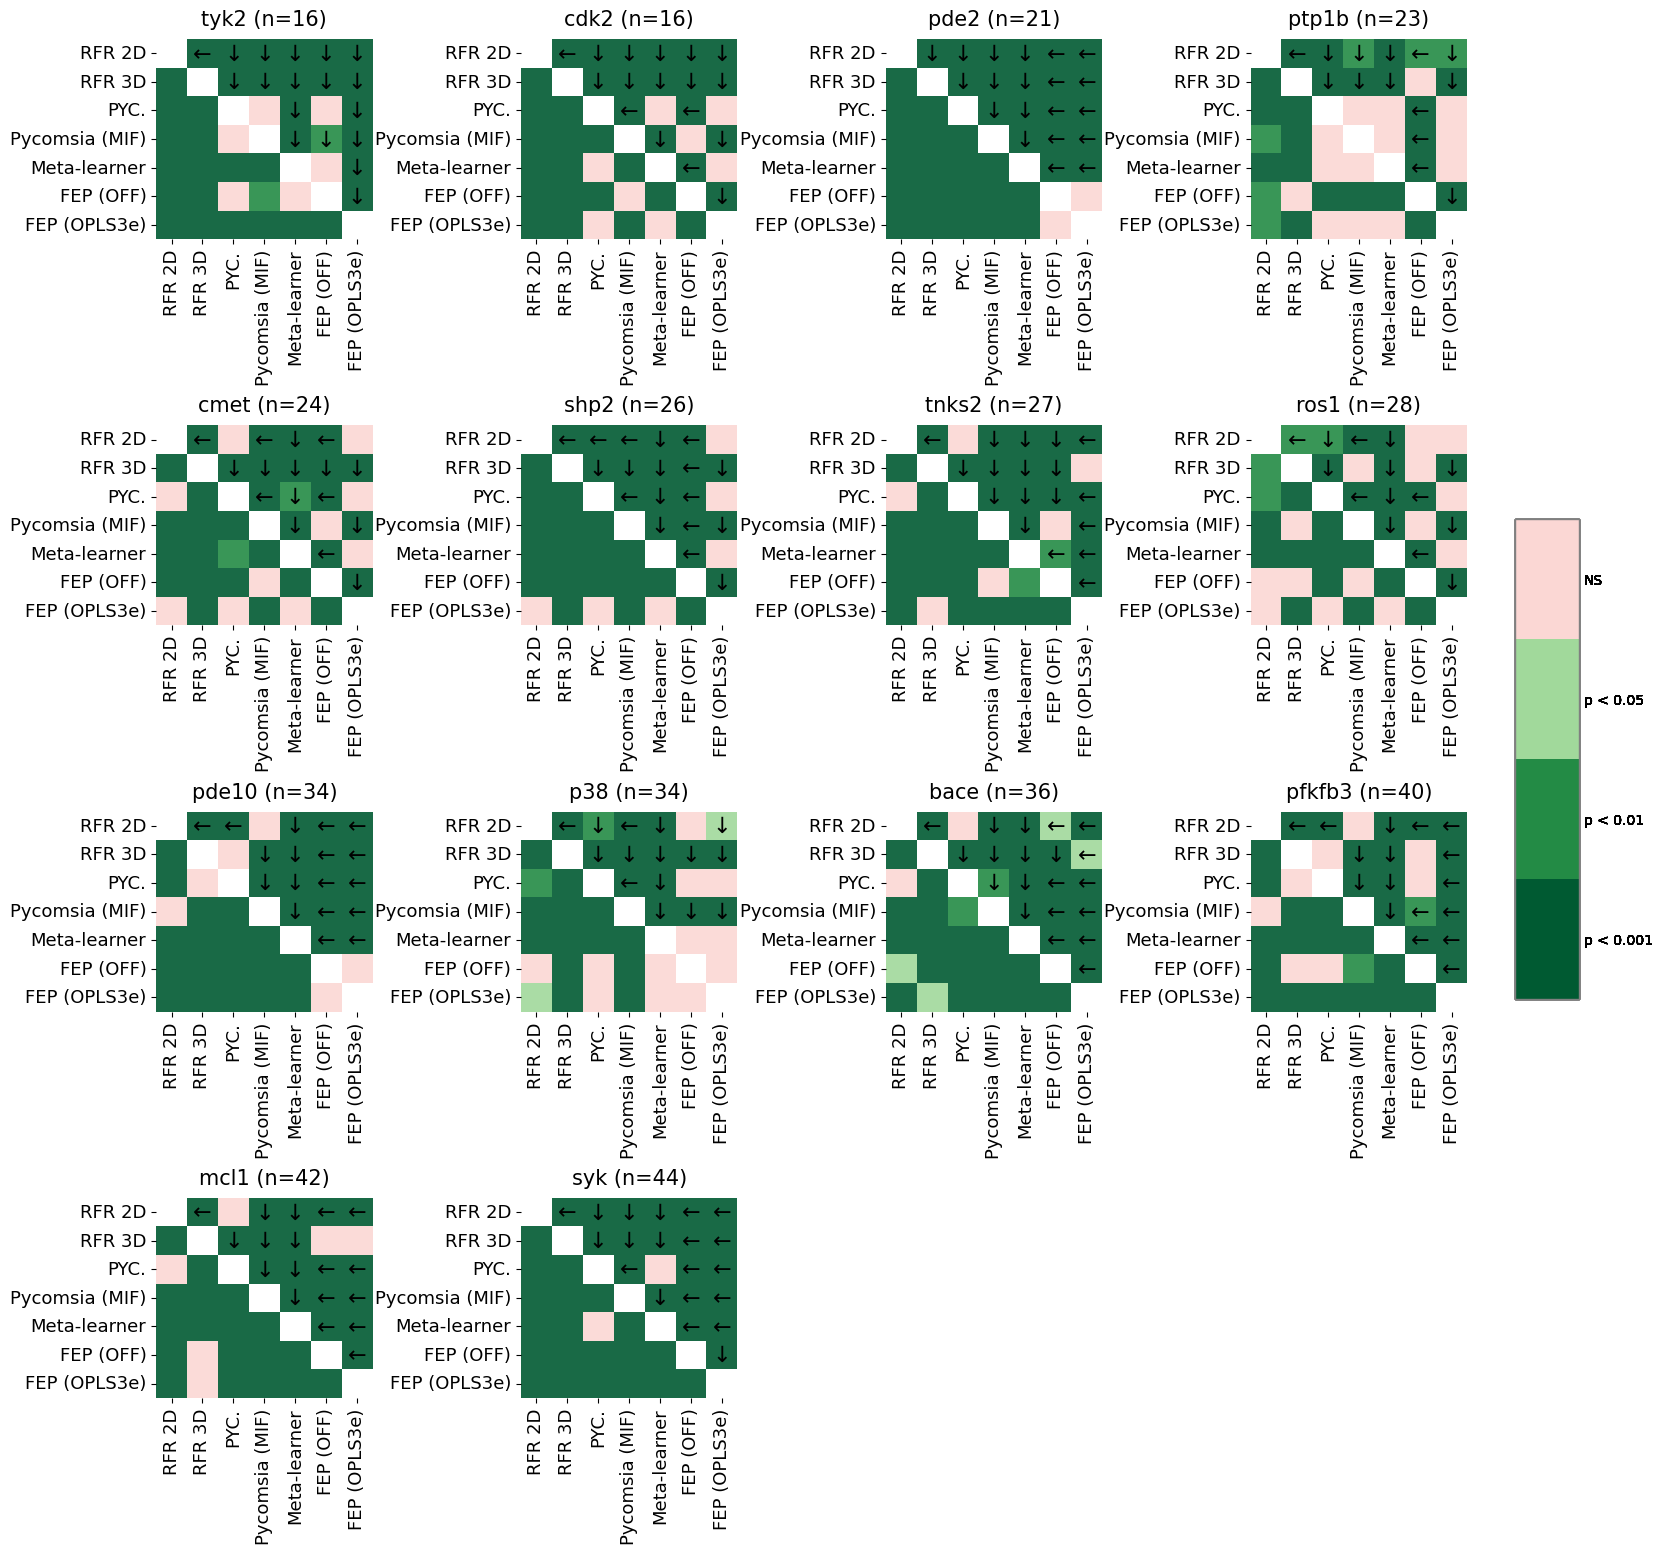

kendalls_tau significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


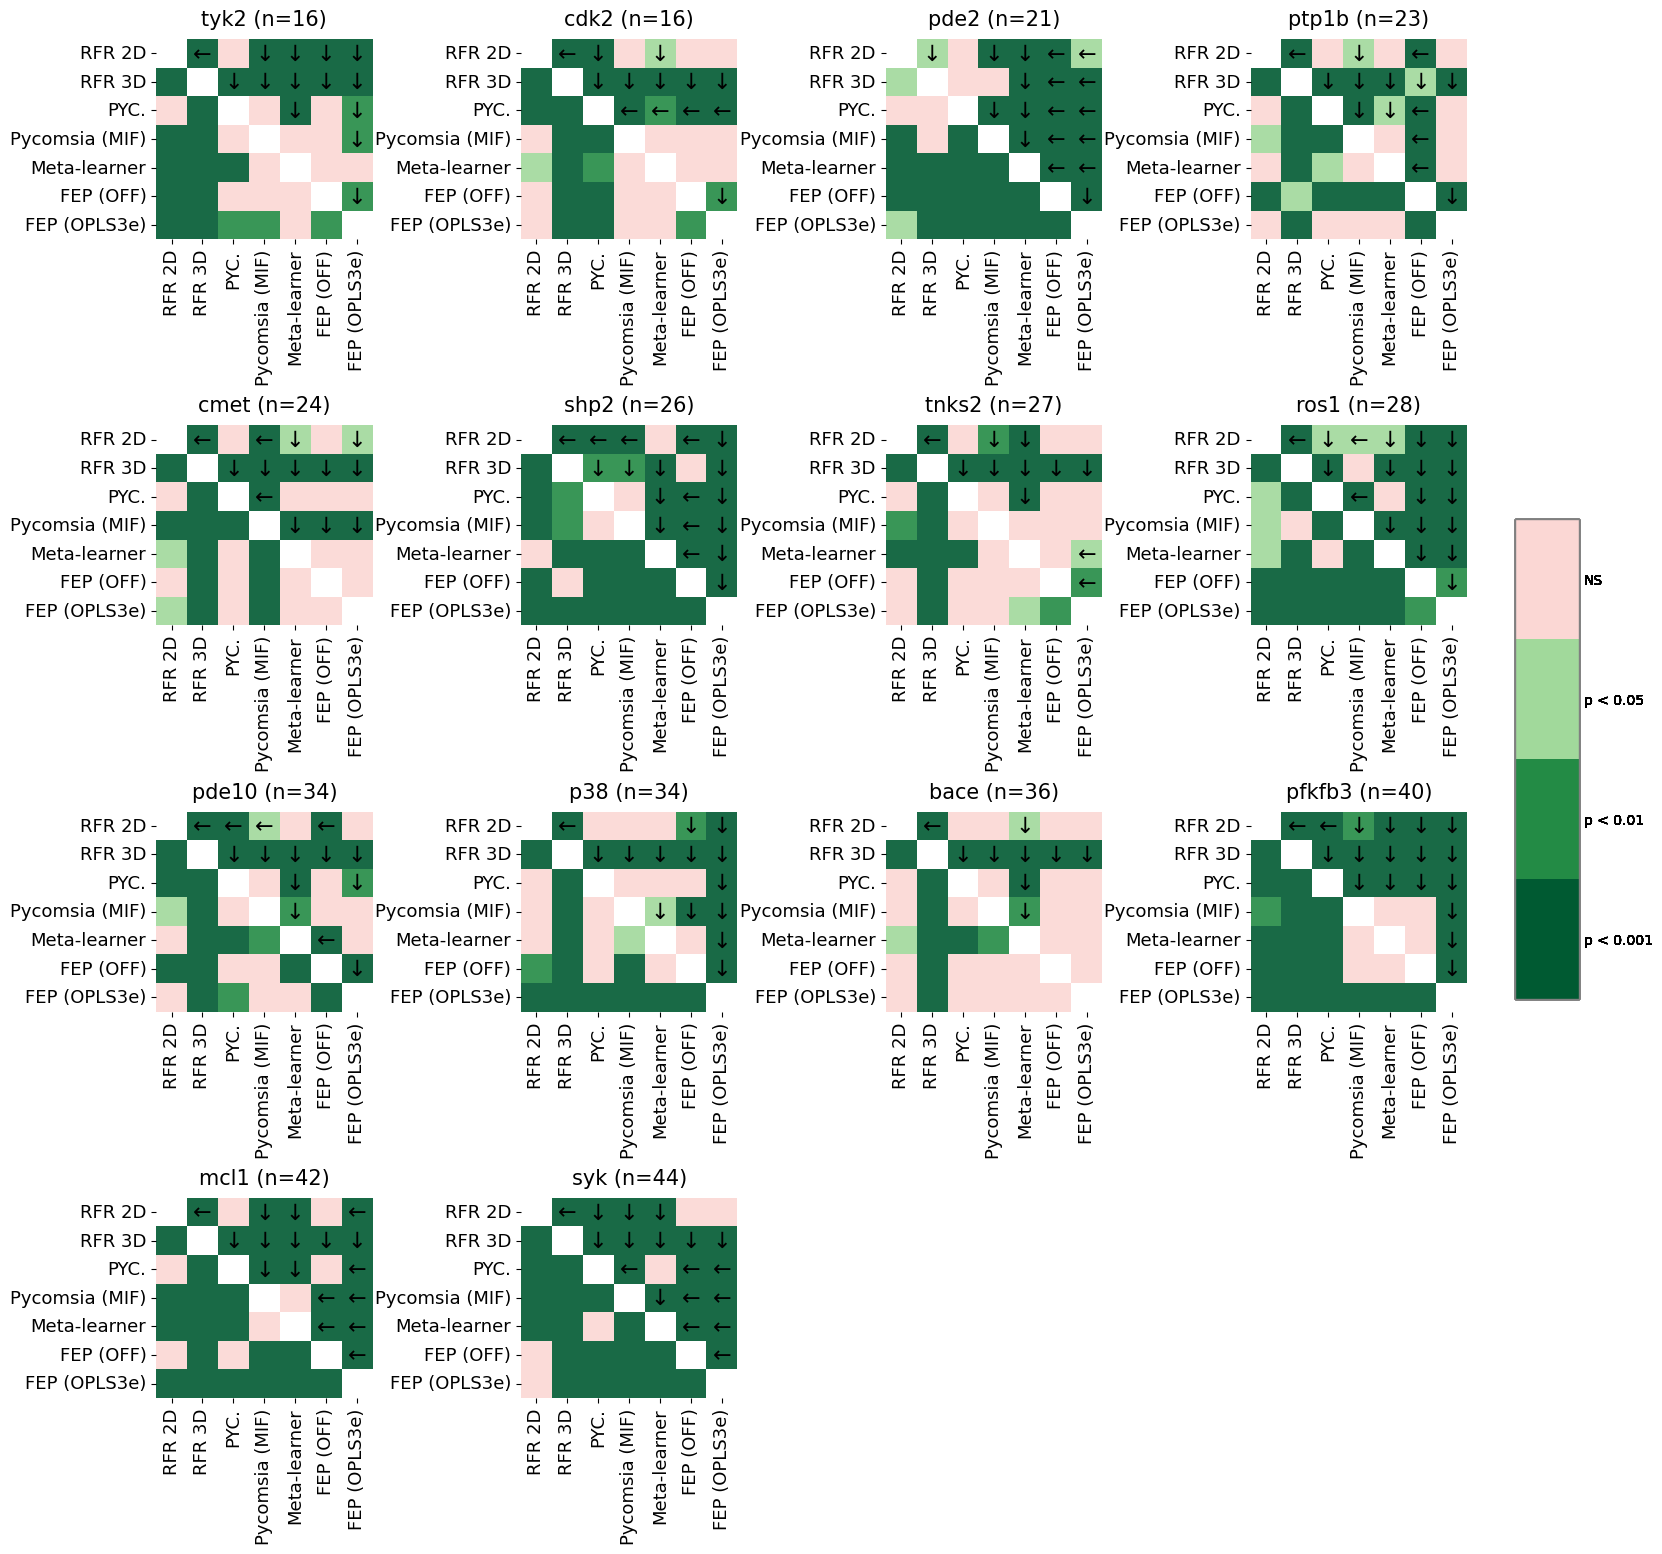

window_tau significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


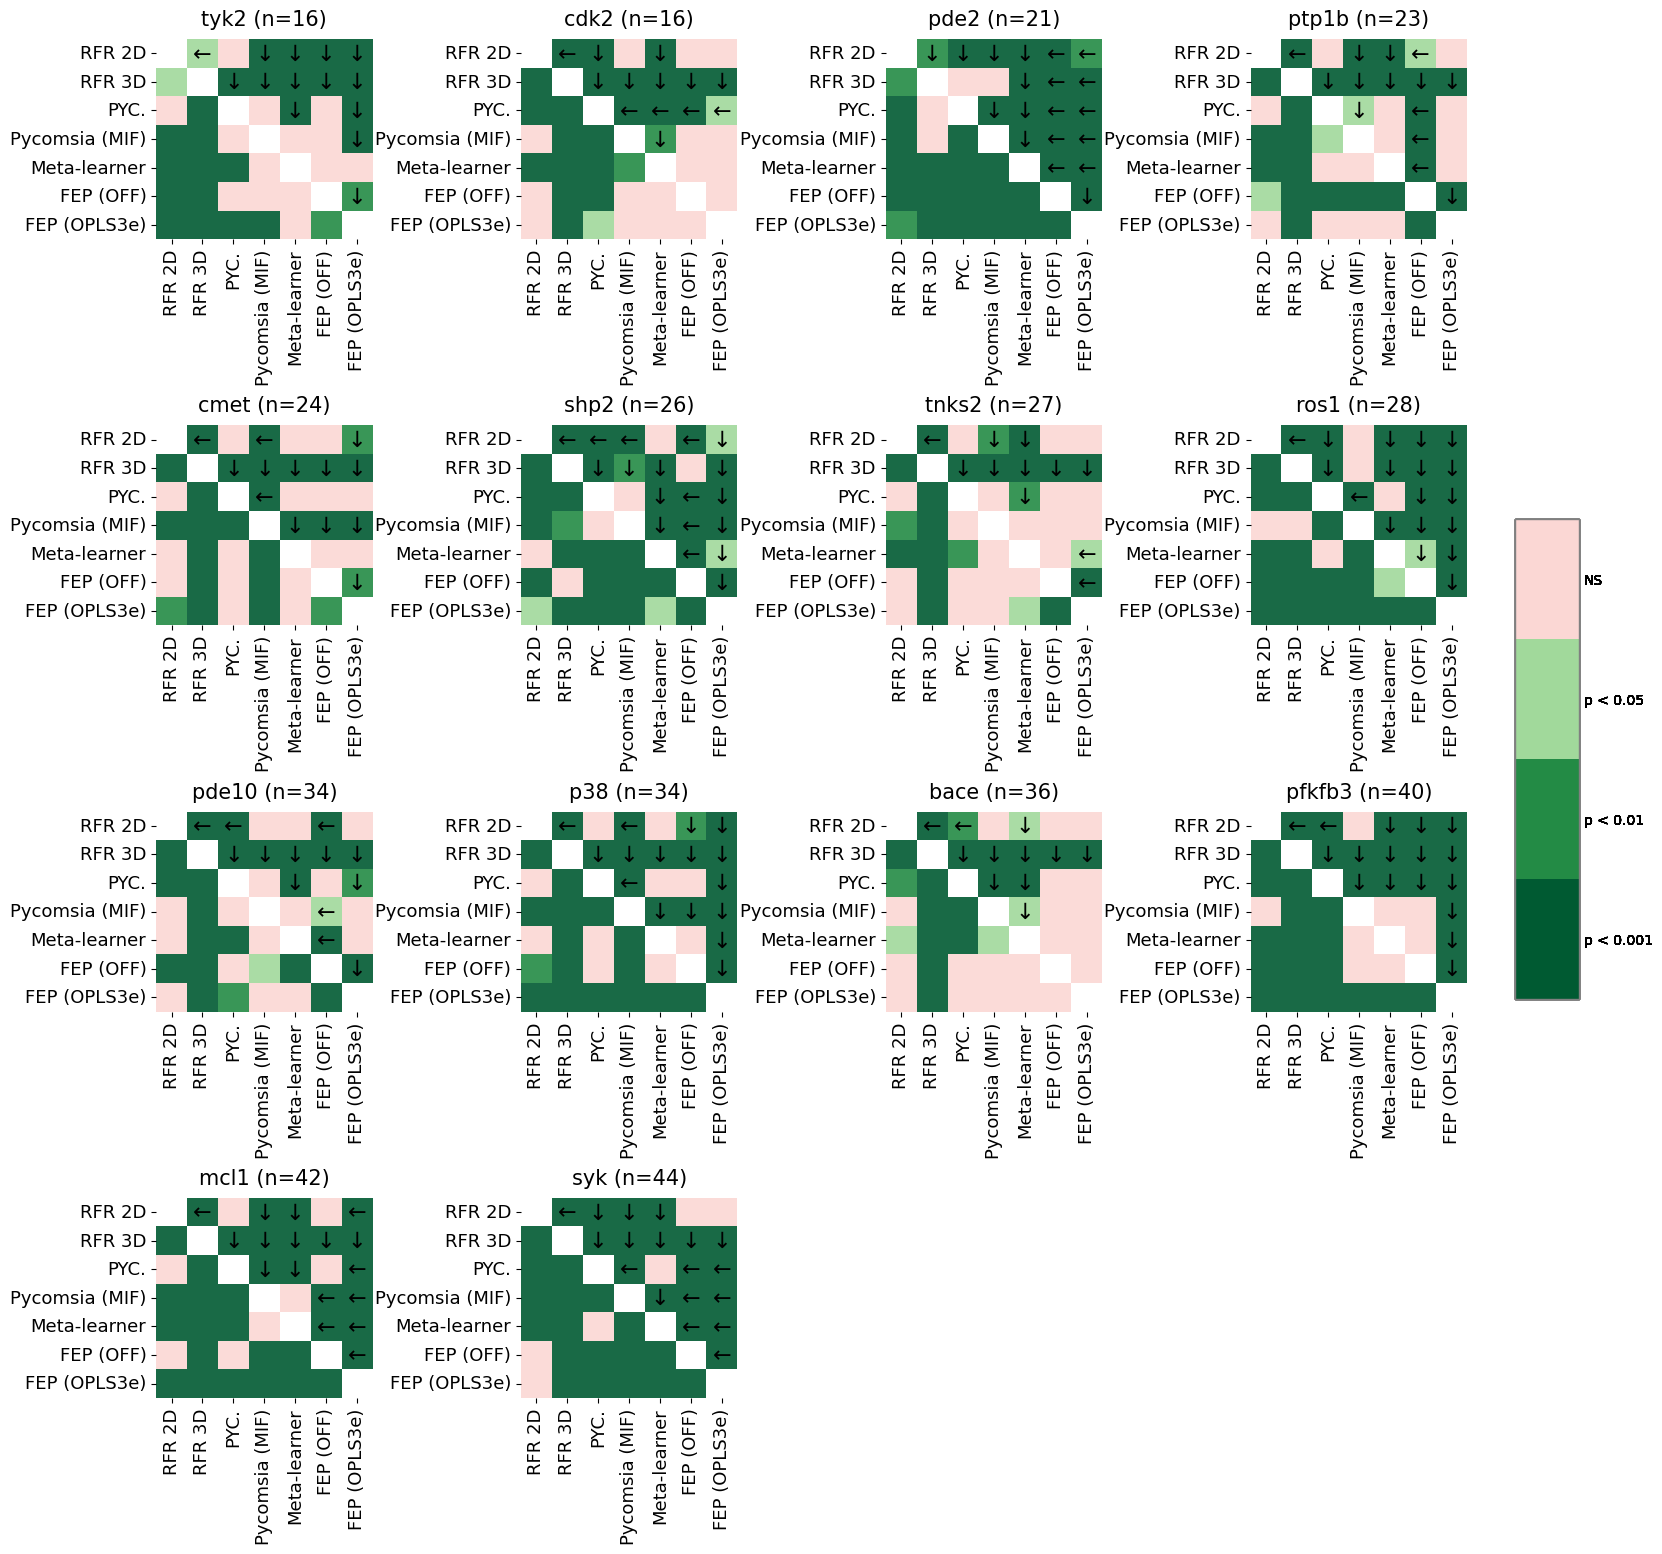

slope_diff significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


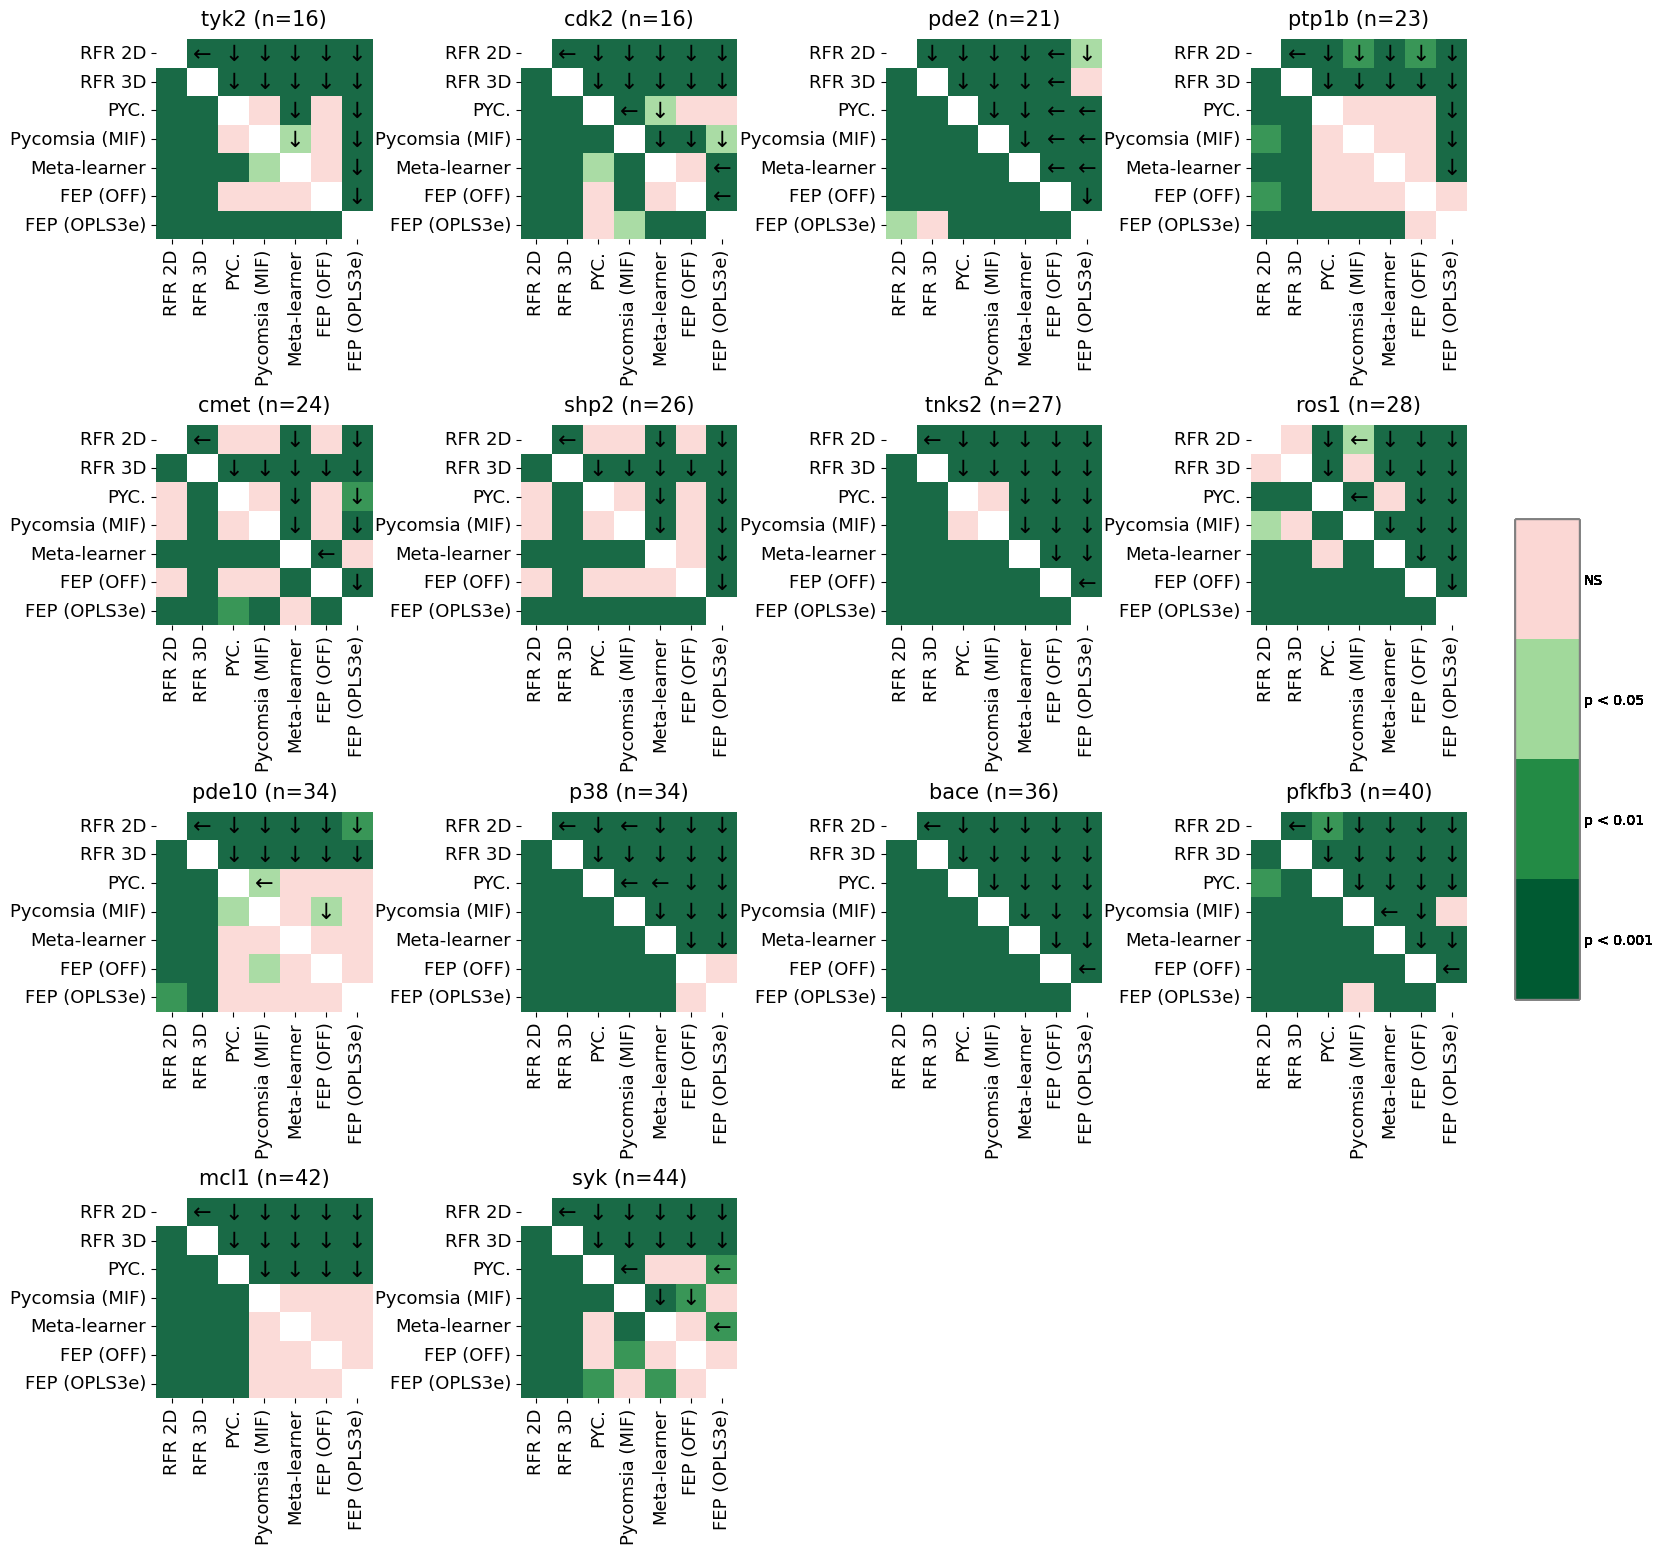

Skipping shp2 for mcc (no Wilcoxon results)


Skipping bace for mcc (no Wilcoxon results)


mcc significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DG/EFFECT_SIZE_PLOTS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


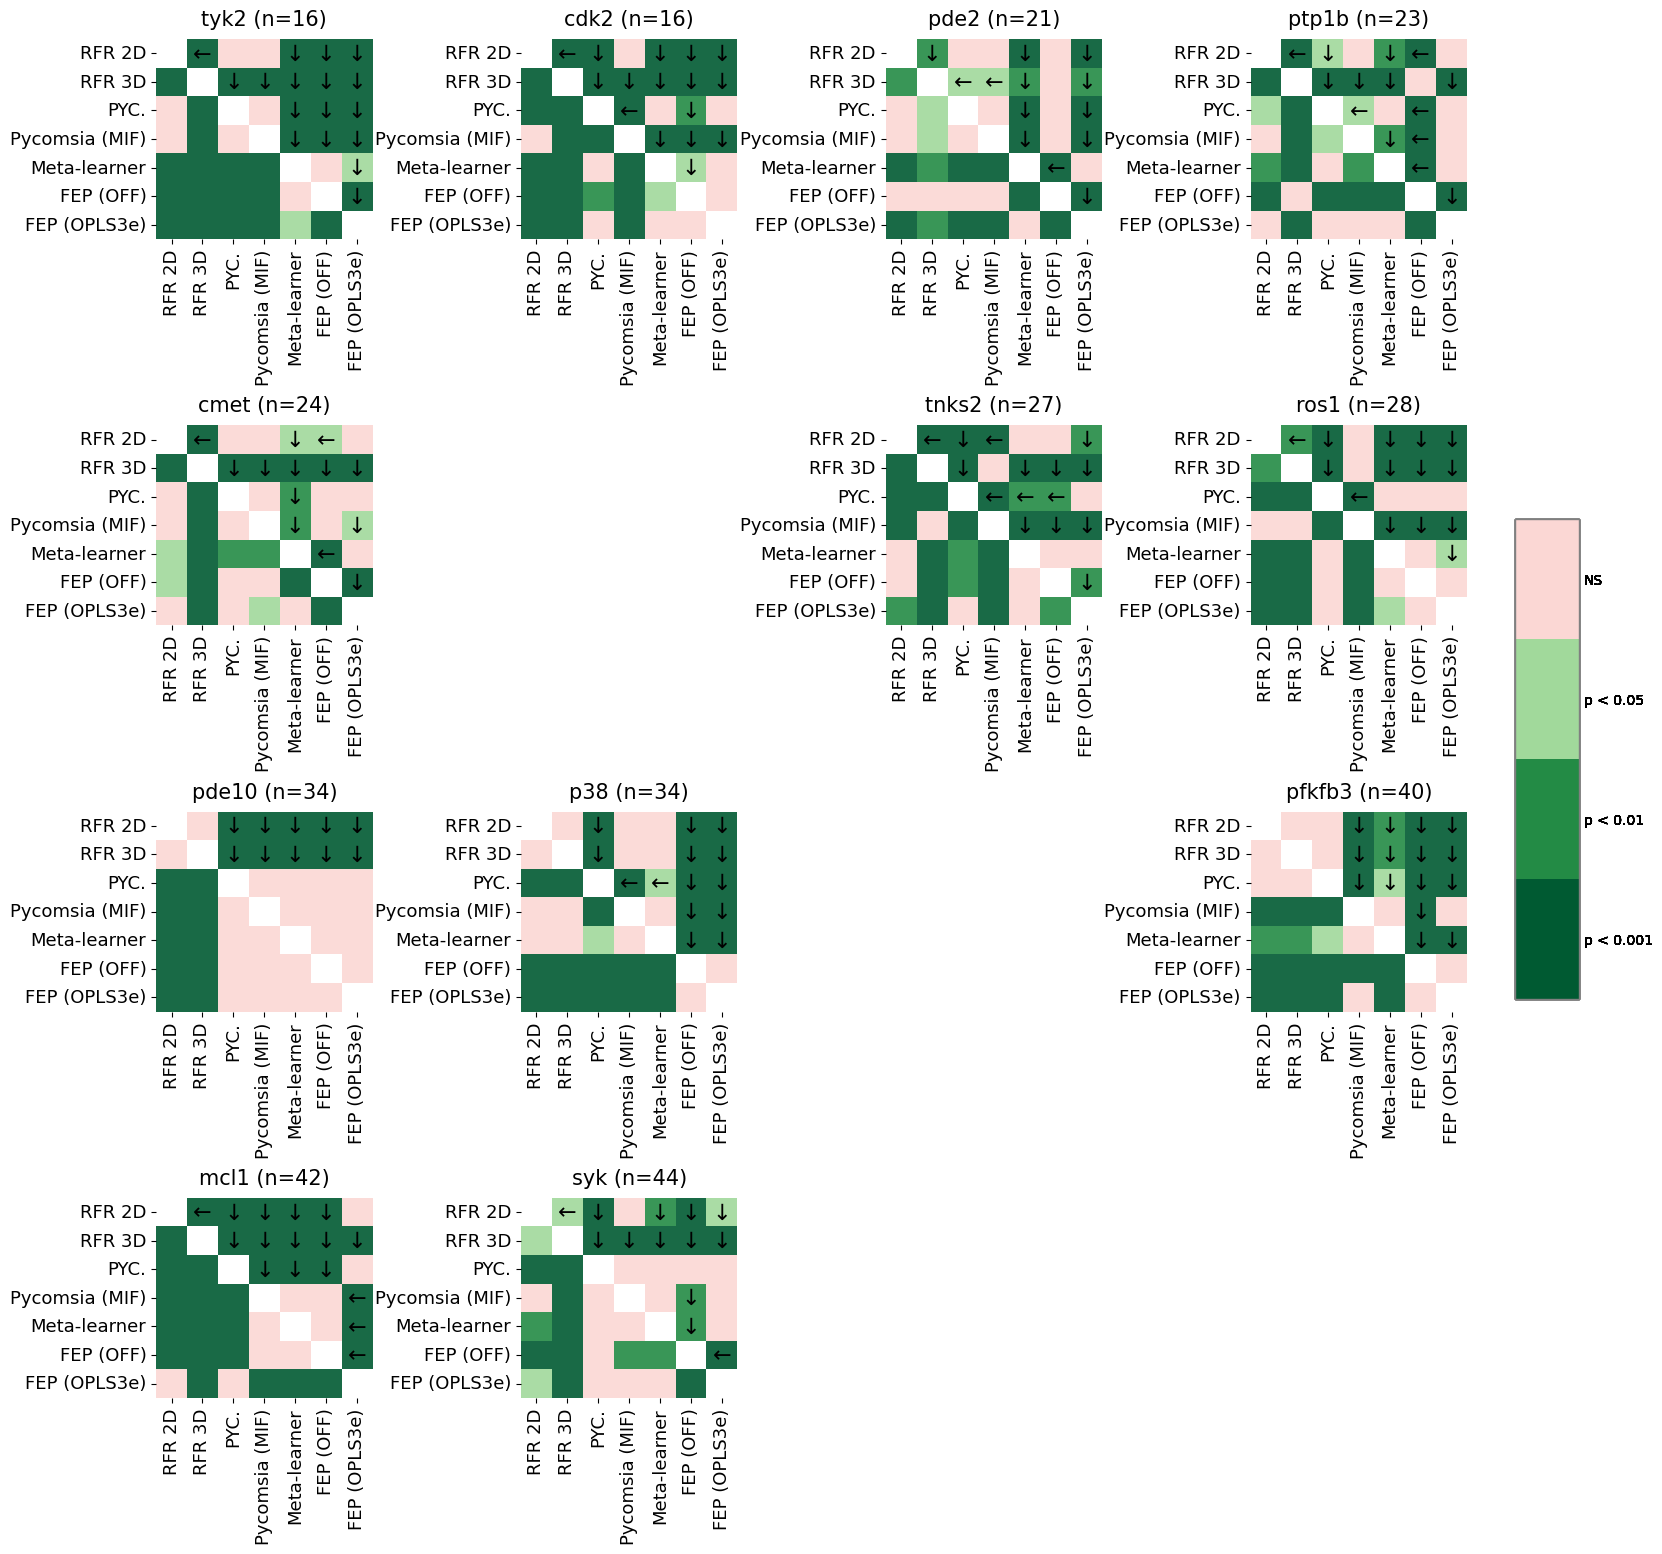

In [6]:
from DDG_ANALYSIS.D_WILCOXON import sign_plot
sign_plot(
    results_all,
    wilcox_posthoc_results,
    DISPLAY_ORDER,
    target_counts_path=target_counts,
    metrics=METRICS,
    targets_to_skip=TARGETS_TO_SKIP,
    n_cols=4,
    arrow_threshold=0.05, # This is the p value for an arrow to show, should be in accordance with the legend (green -> has an arrow)
    alpha=0.9, # this alpha is how seethrough plot is, not to be mixed up with ALPHA (p value)
)

### Effect size & Significance (Based on wilcoxon)

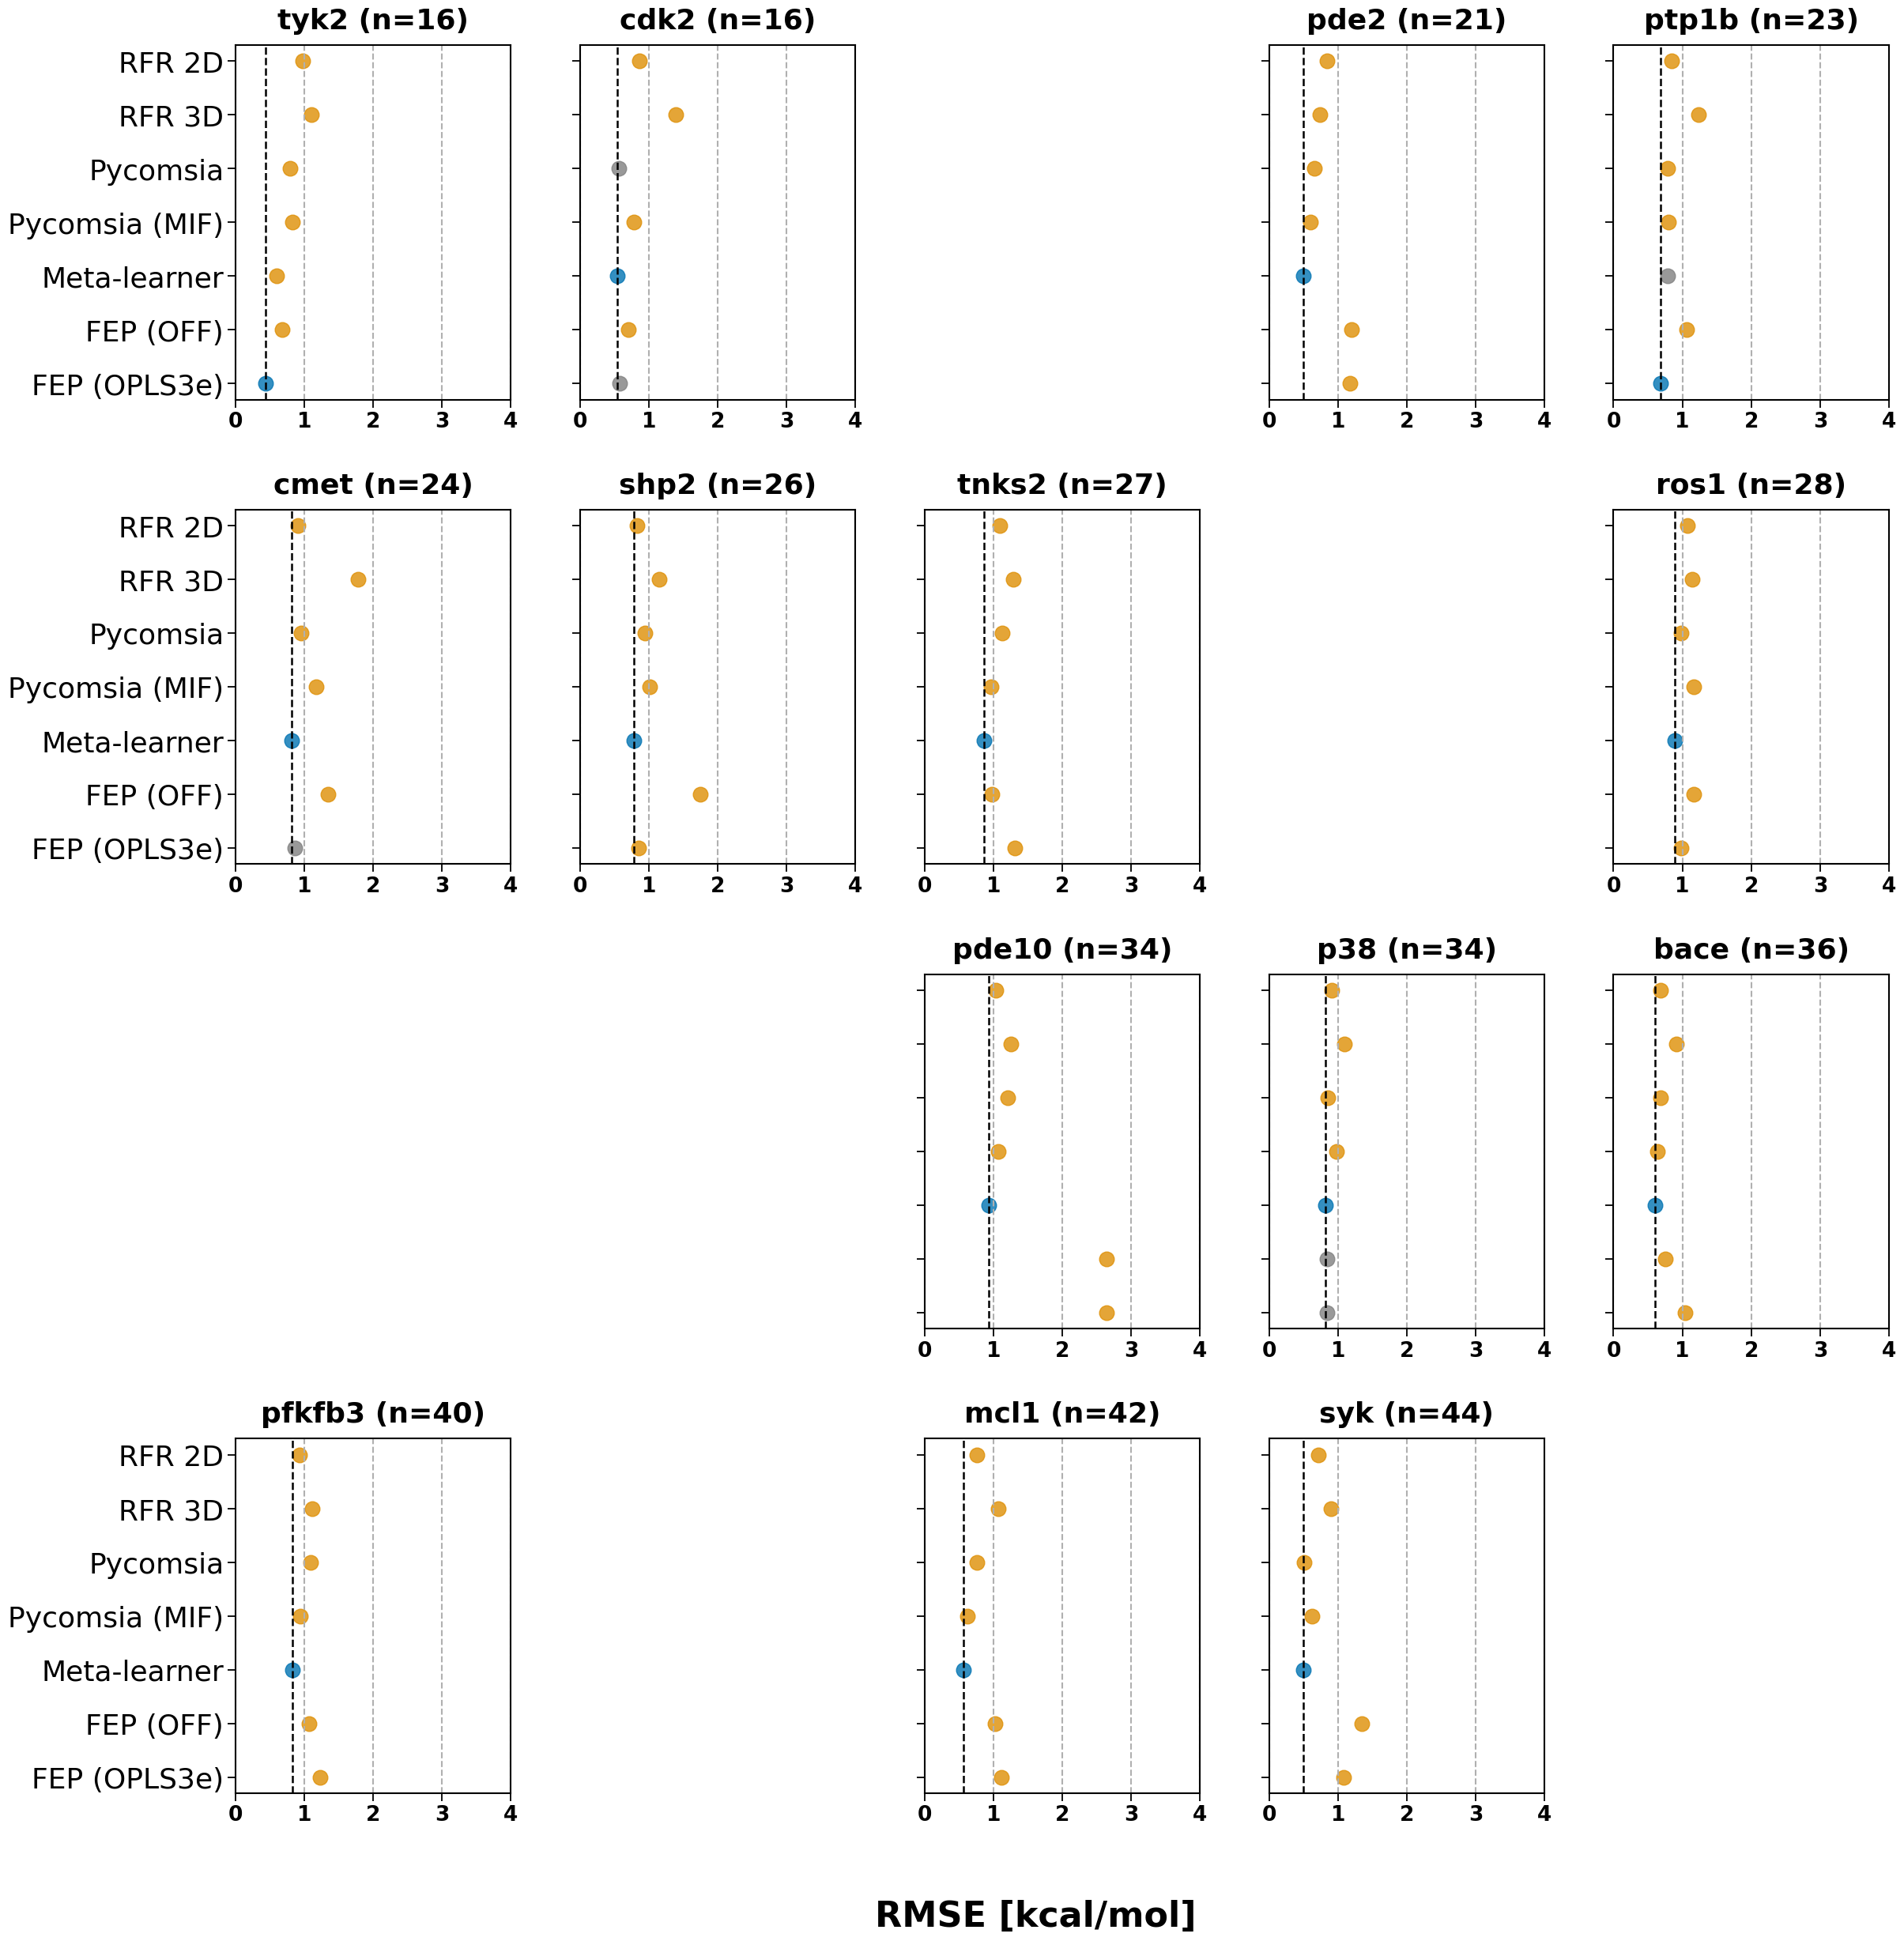


Effect-size counts for metric 'rmse':
- FEP (OFF): 0 targets → []
- FEP (OPLS3e): 2 targets → ['tyk2', 'ptp1b']
- Meta-learner: 9 targets → ['cdk2', 'pde2', 'cmet', 'shp2', 'tnks2', 'pde10', 'bace', 'mcl1', 'syk']
- Pycomsia: 0 targets → []
- Pycomsia (MIF): 0 targets → []
- RFR 2D: 0 targets → []
- RFR 3D: 0 targets → []


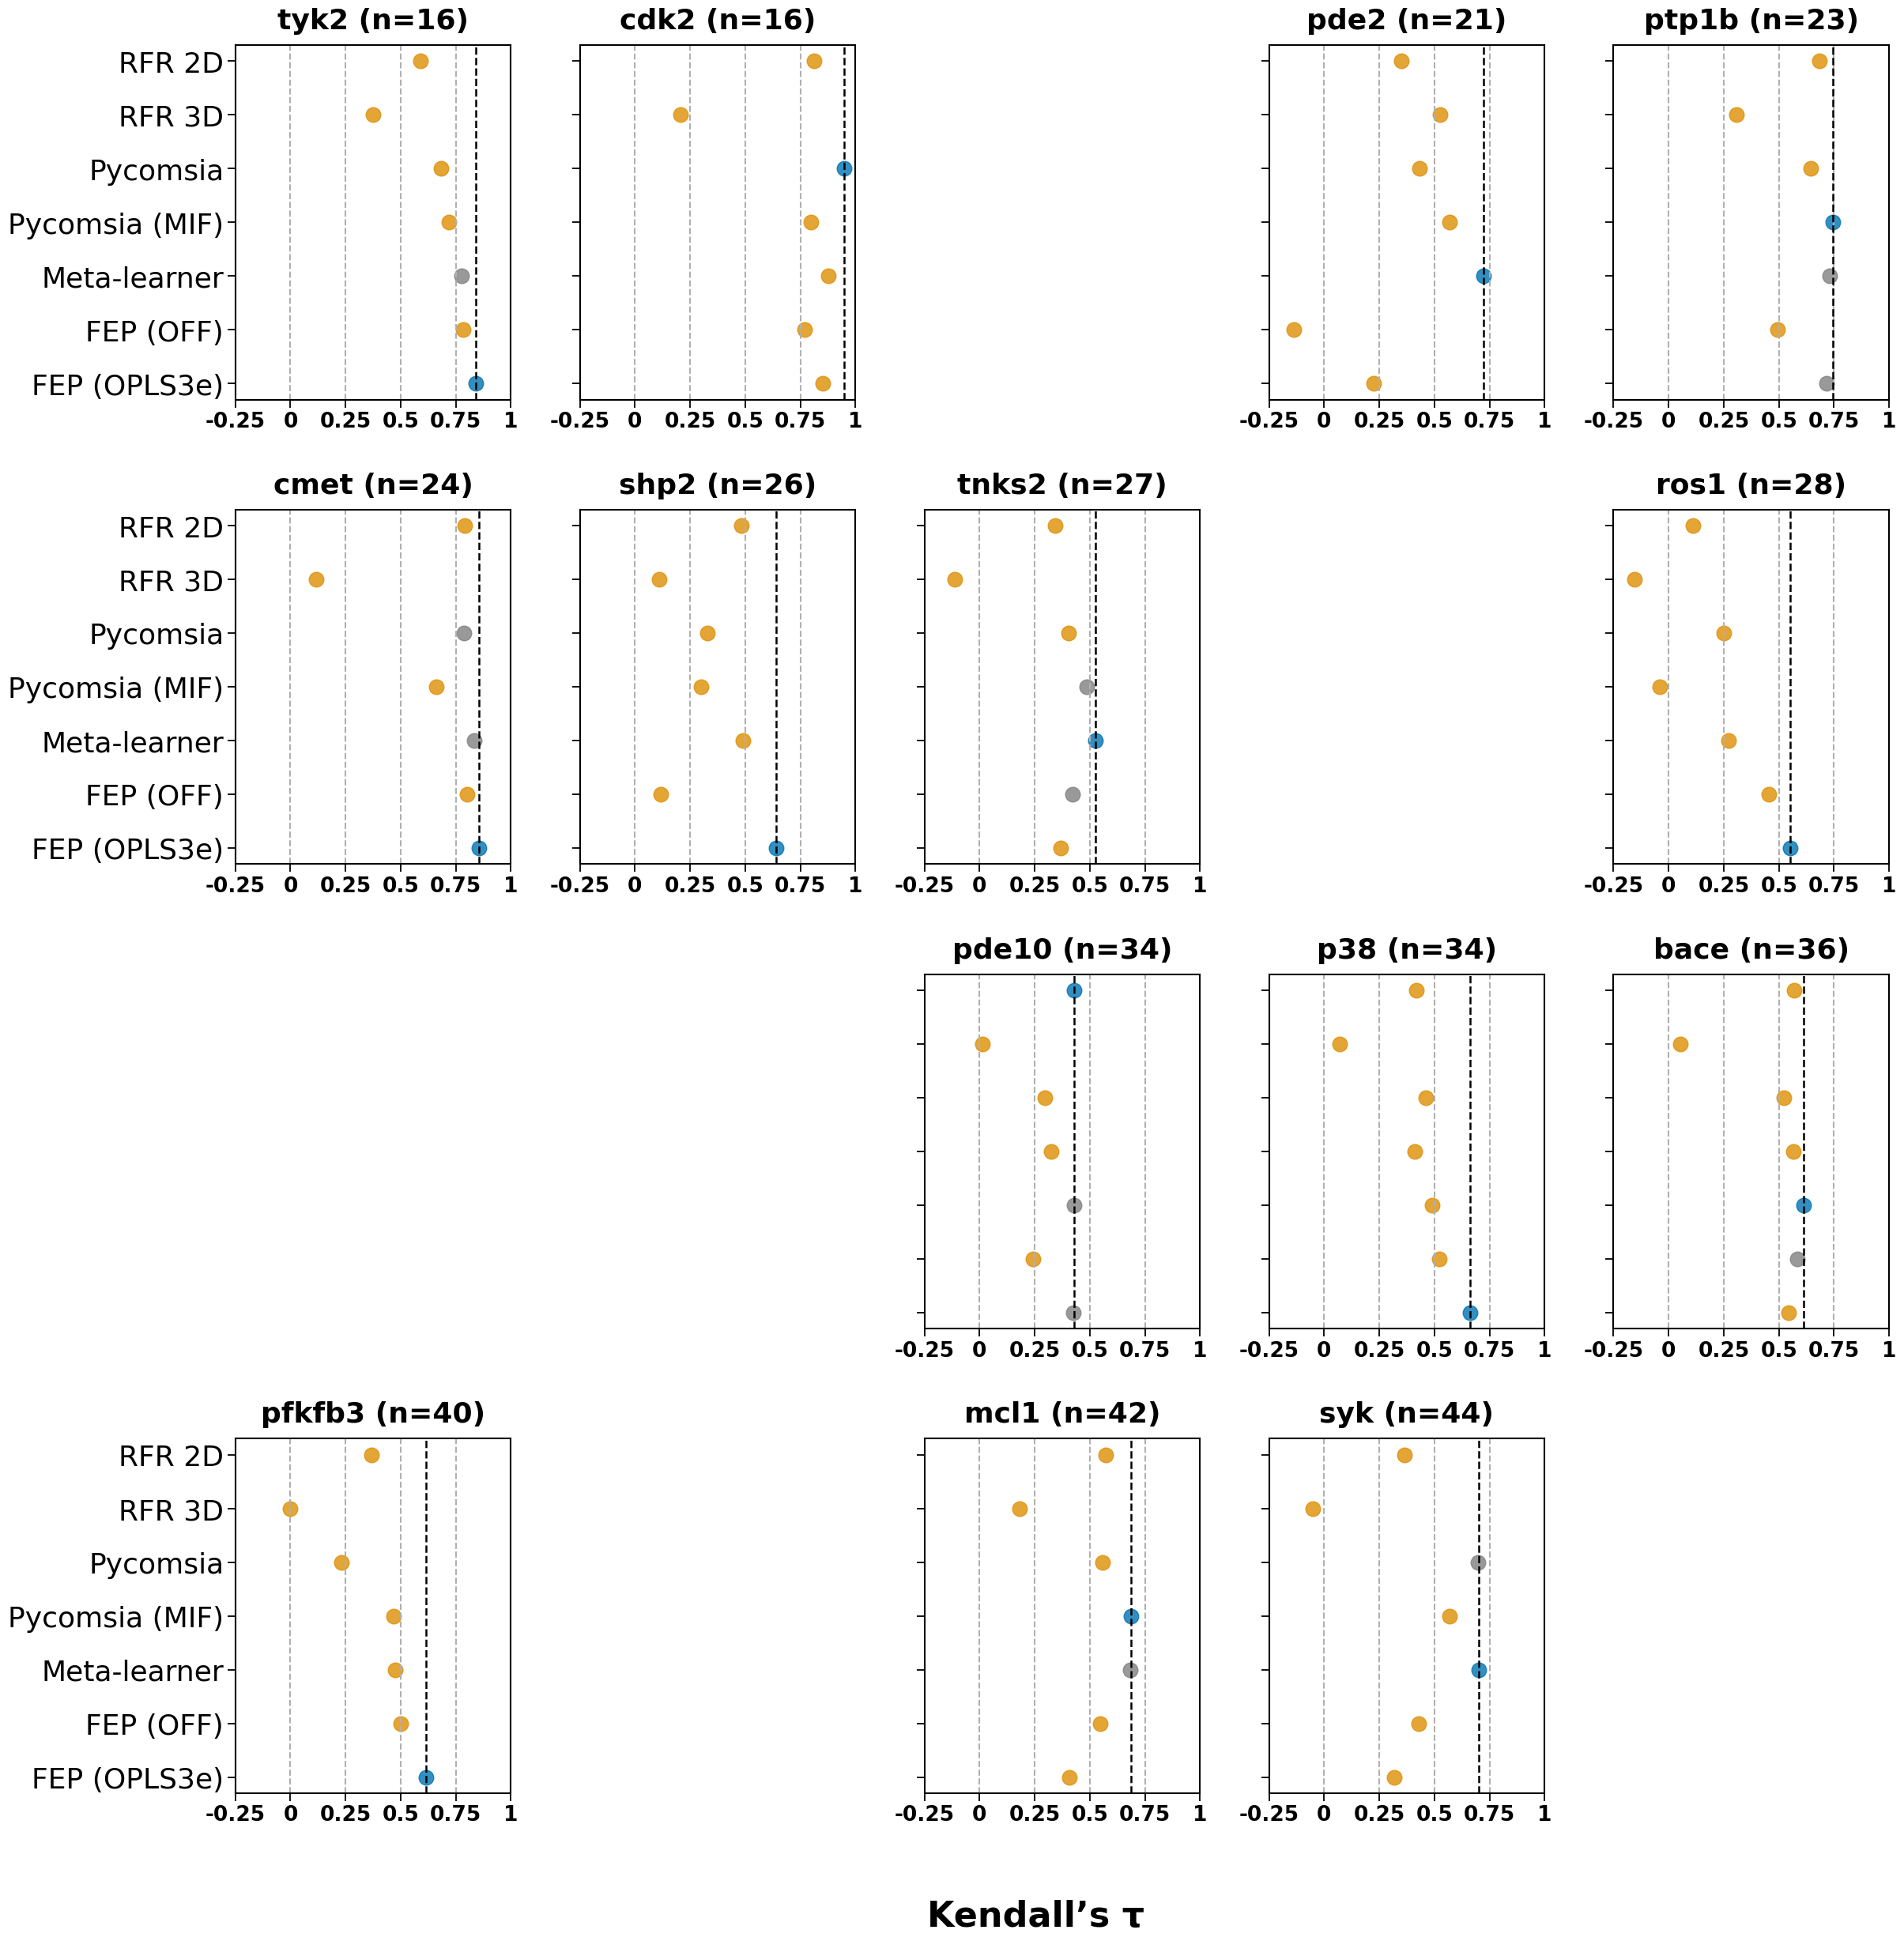


Effect-size counts for metric 'kendalls_tau':
- FEP (OFF): 0 targets → []
- FEP (OPLS3e): 6 targets → ['tyk2', 'cmet', 'shp2', 'ros1', 'p38', 'pfkfb3']
- Meta-learner: 4 targets → ['pde2', 'tnks2', 'bace', 'syk']
- Pycomsia: 1 targets → ['cdk2']
- Pycomsia (MIF): 2 targets → ['ptp1b', 'mcl1']
- RFR 2D: 1 targets → ['pde10']
- RFR 3D: 0 targets → []


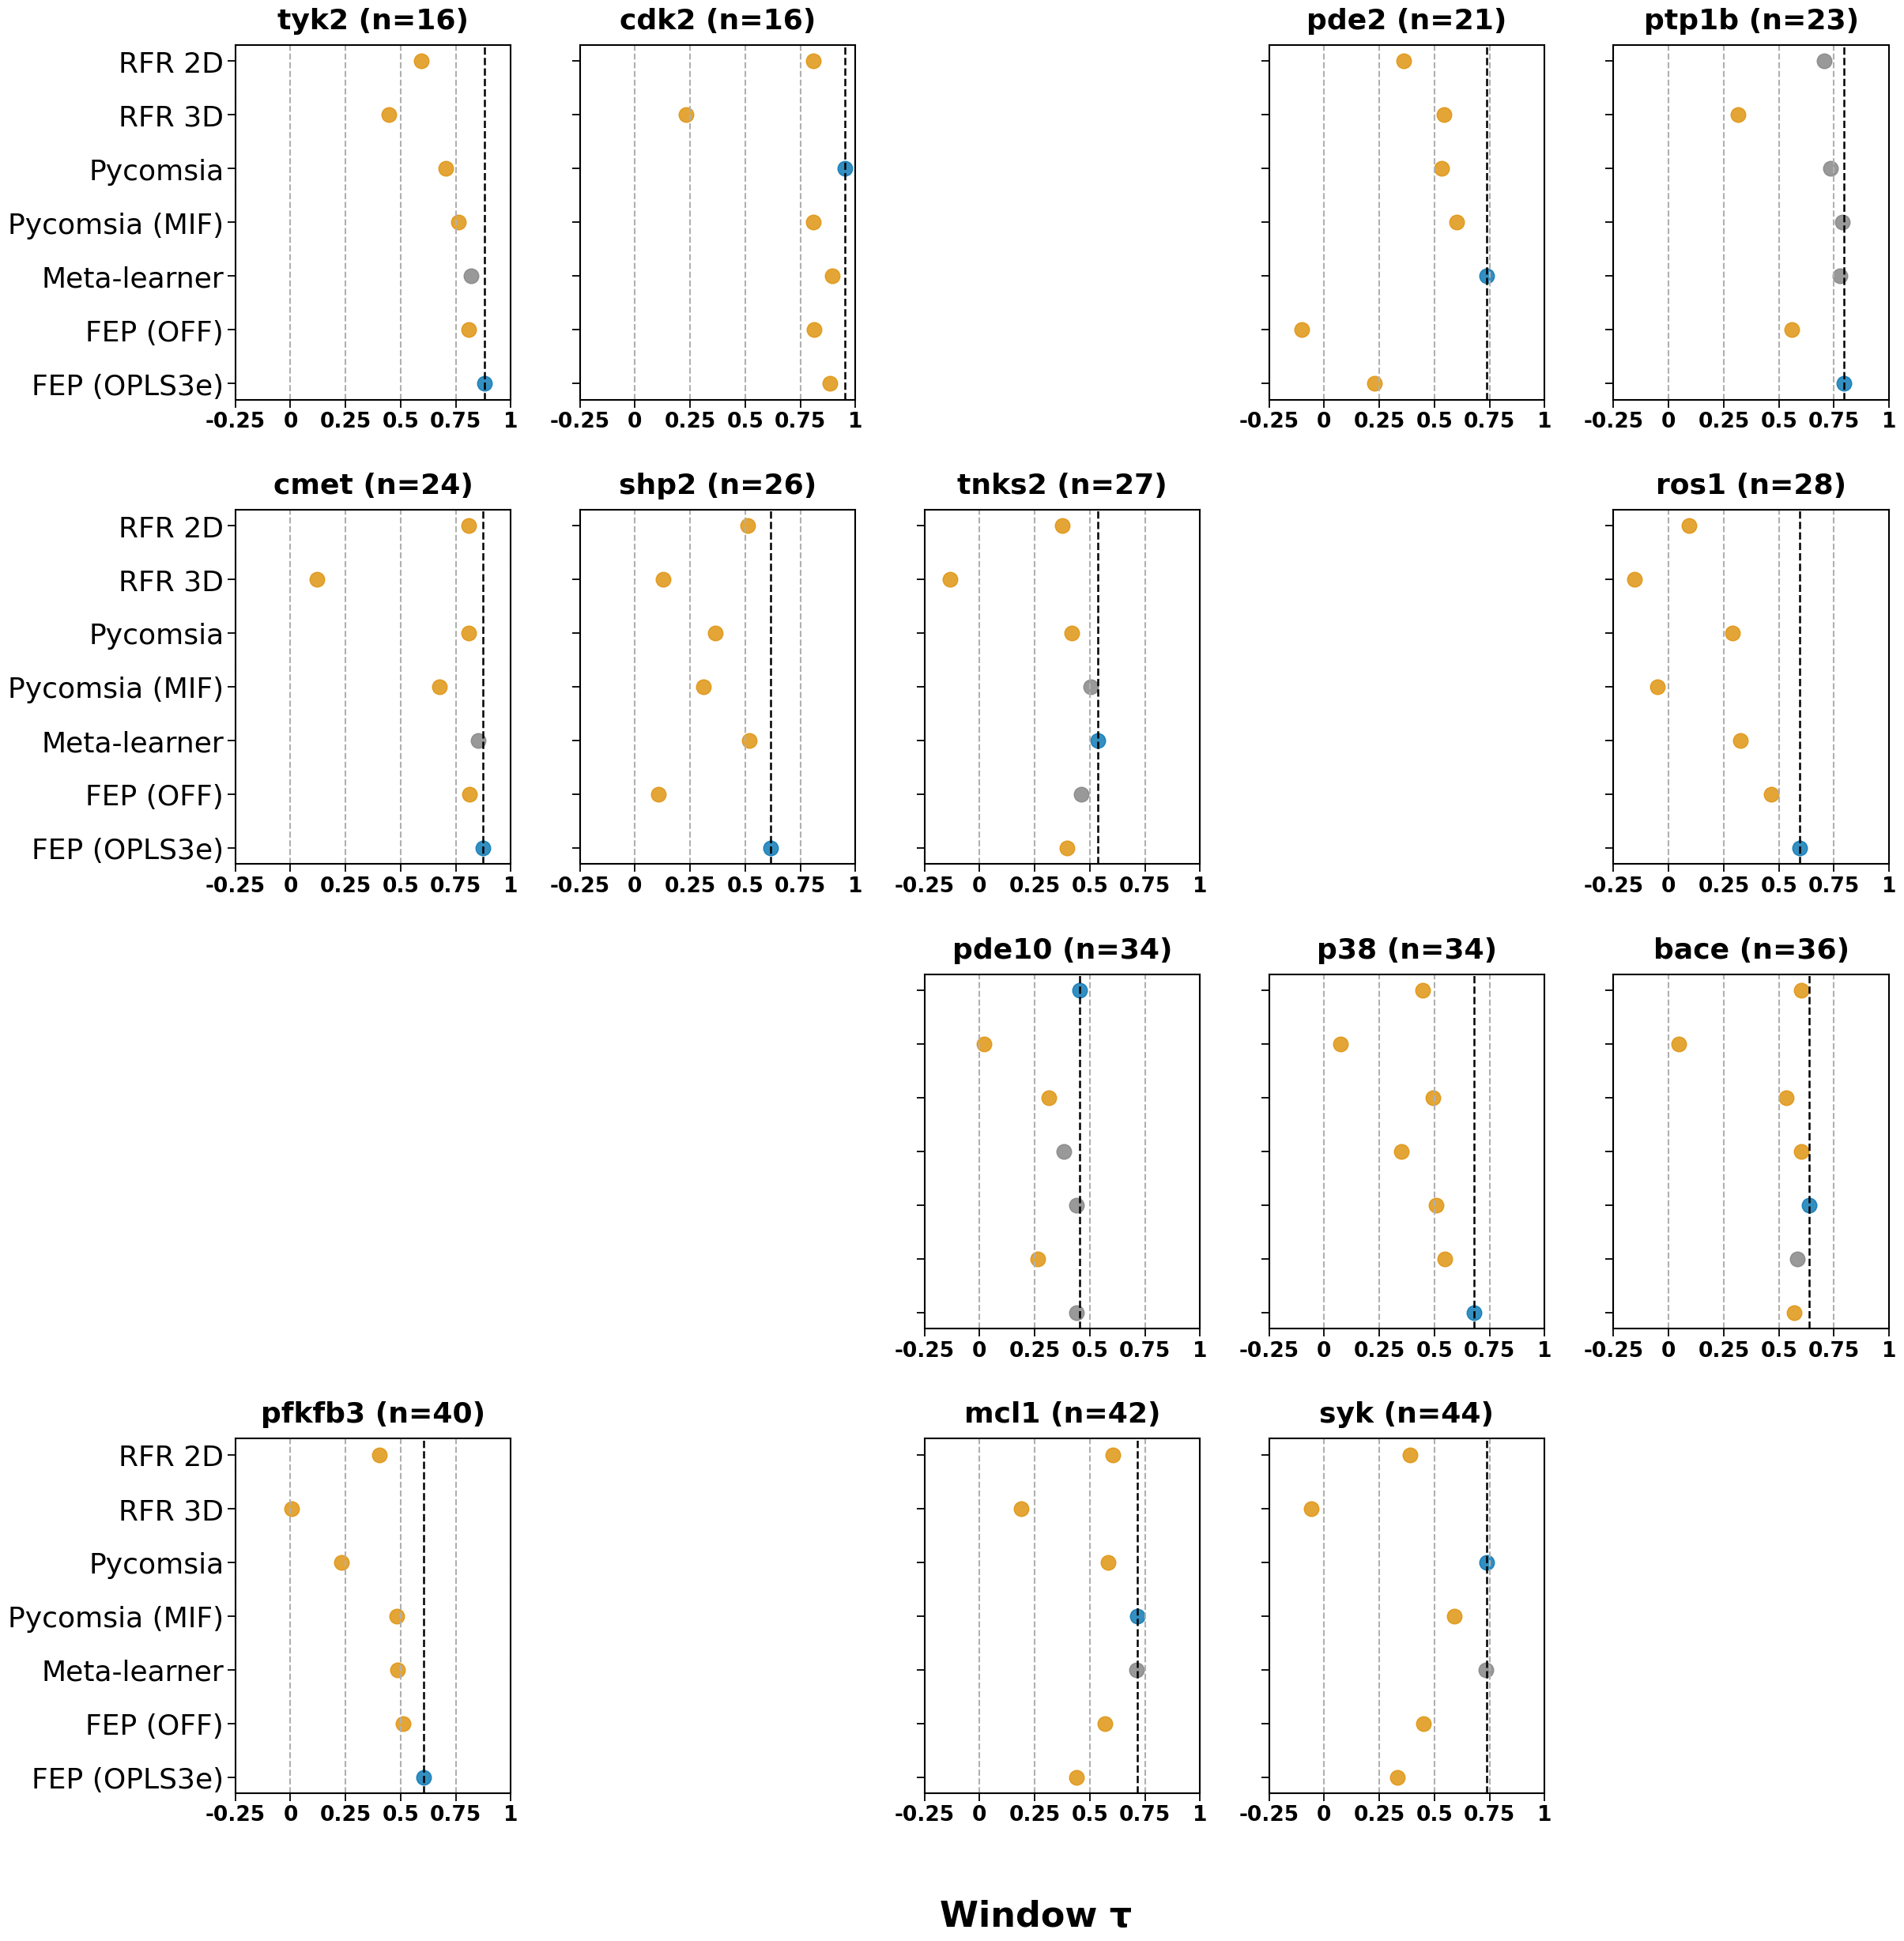


Effect-size counts for metric 'window_tau':
- FEP (OFF): 0 targets → []
- FEP (OPLS3e): 7 targets → ['tyk2', 'ptp1b', 'cmet', 'shp2', 'ros1', 'p38', 'pfkfb3']
- Meta-learner: 3 targets → ['pde2', 'tnks2', 'bace']
- Pycomsia: 2 targets → ['cdk2', 'syk']
- Pycomsia (MIF): 1 targets → ['mcl1']
- RFR 2D: 1 targets → ['pde10']
- RFR 3D: 0 targets → []


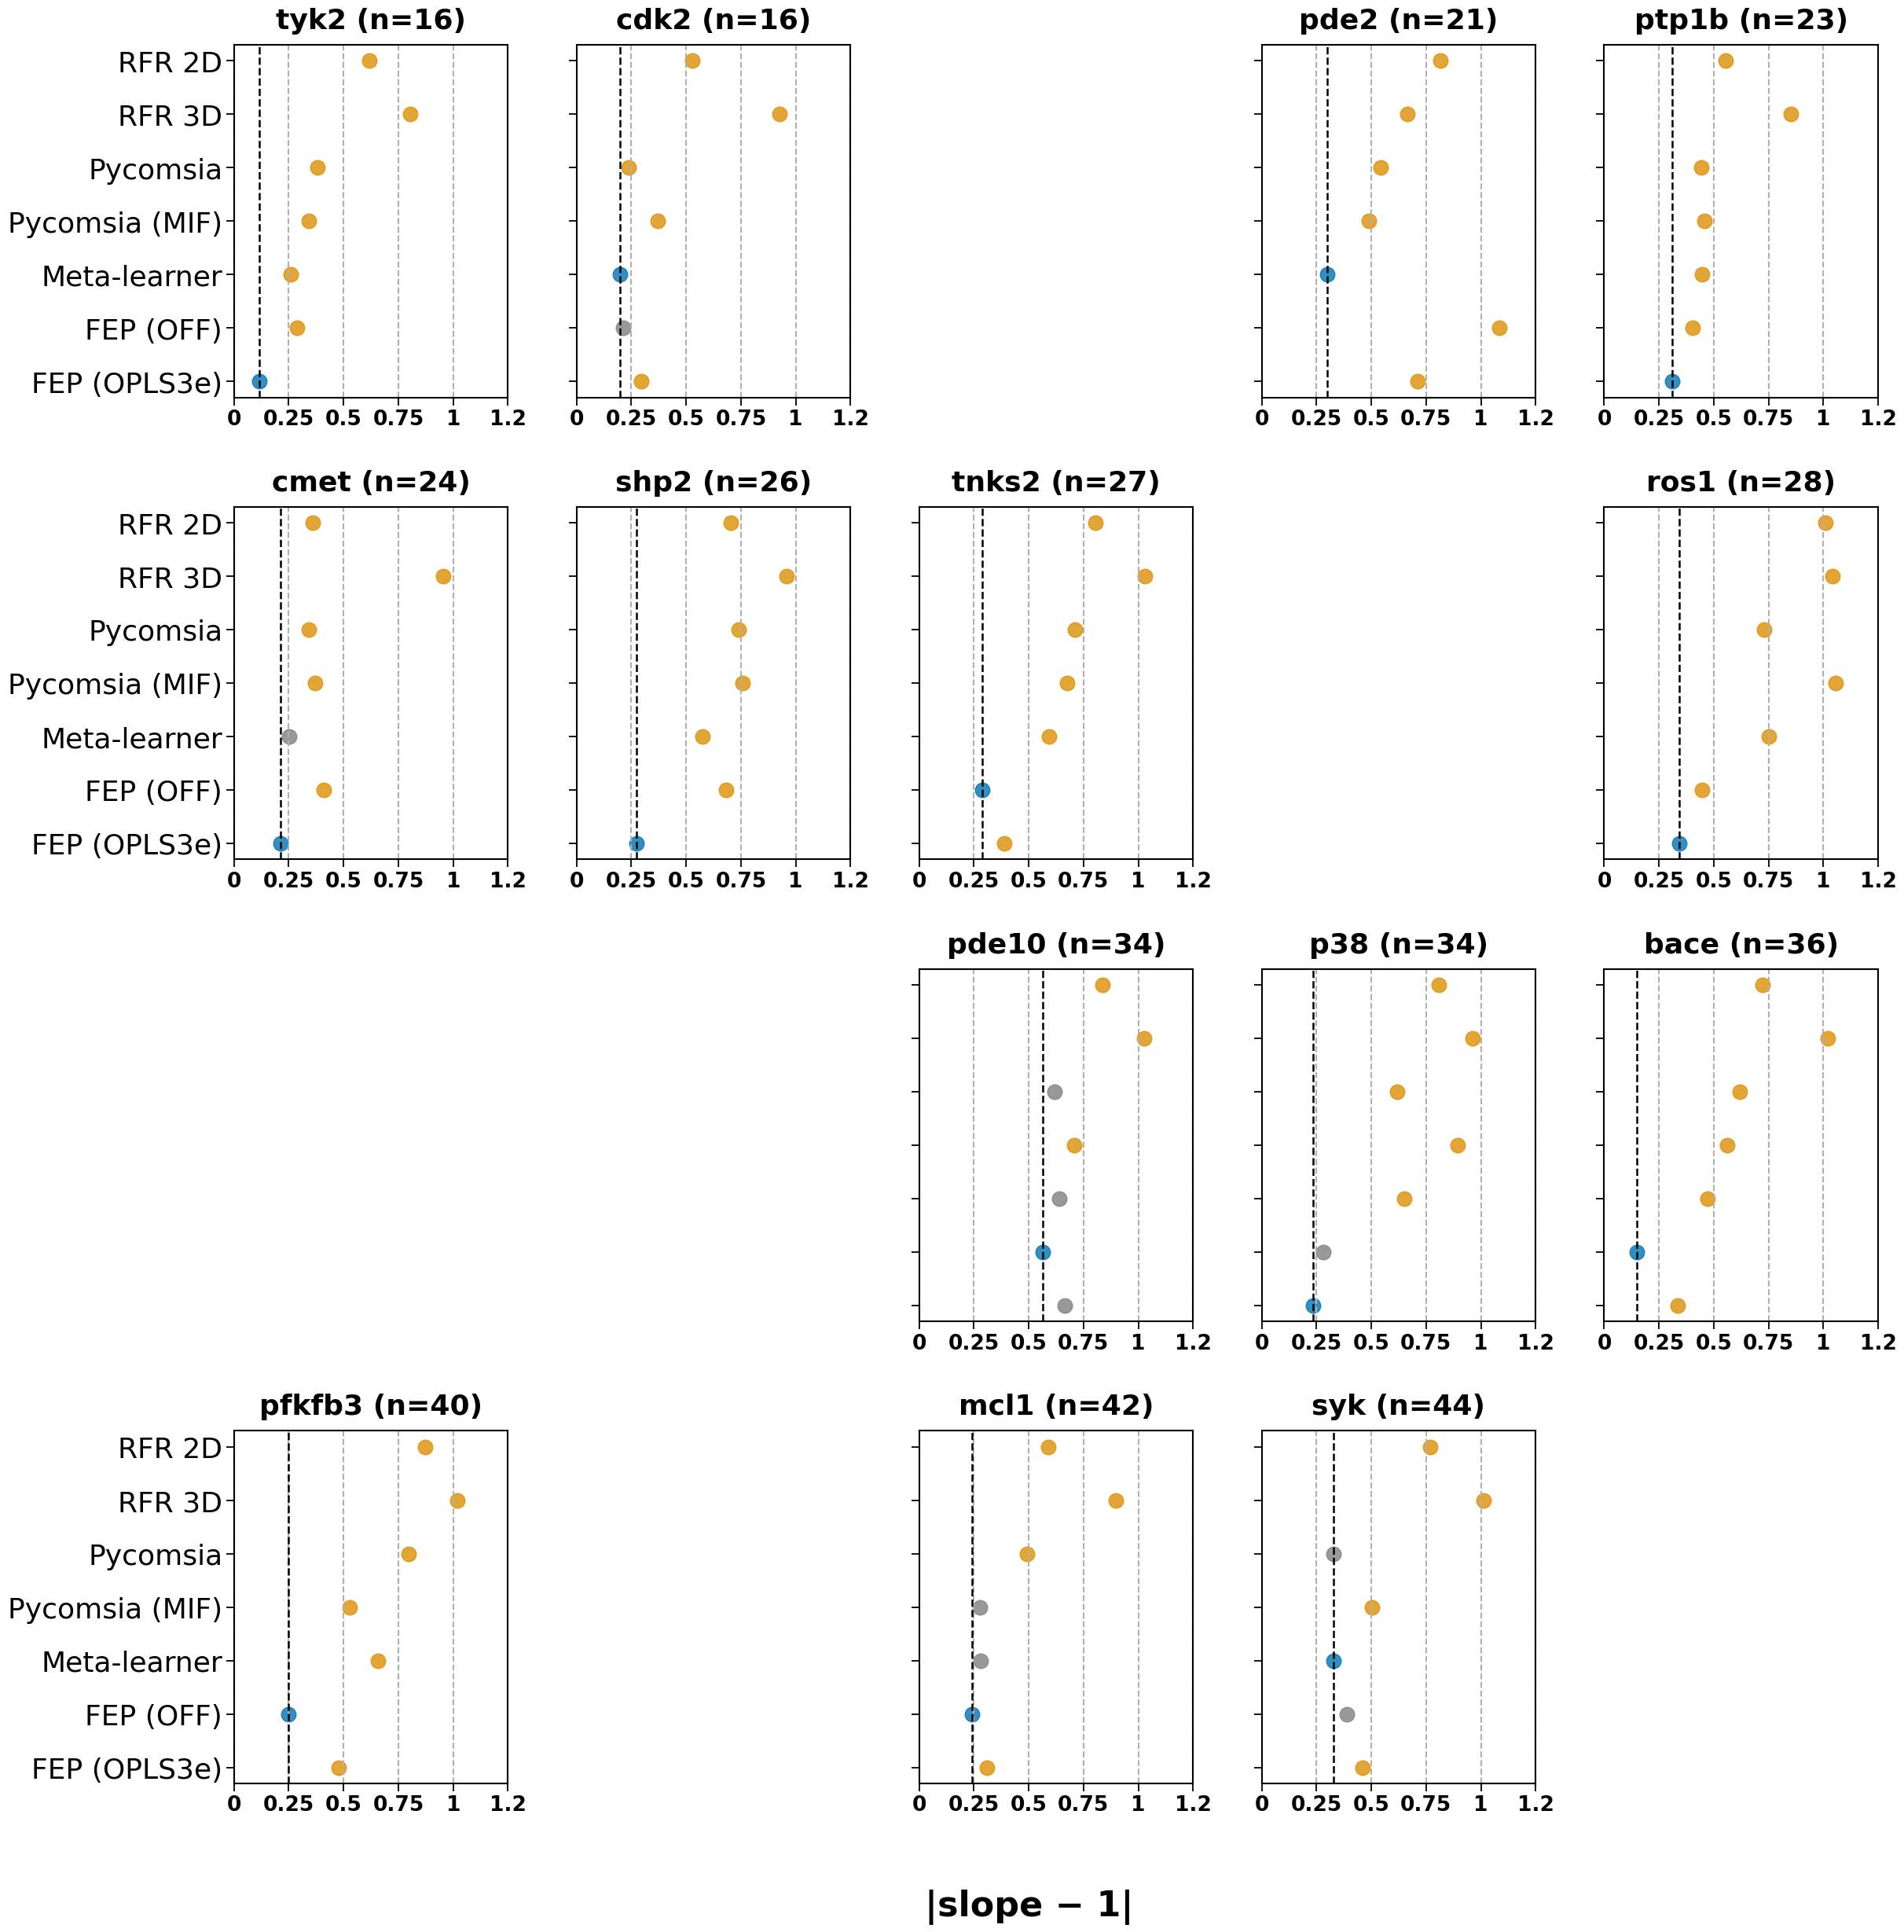


Effect-size counts for metric 'slope_diff':
- FEP (OFF): 5 targets → ['tnks2', 'pde10', 'bace', 'pfkfb3', 'mcl1']
- FEP (OPLS3e): 6 targets → ['tyk2', 'ptp1b', 'cmet', 'shp2', 'ros1', 'p38']
- Meta-learner: 3 targets → ['cdk2', 'pde2', 'syk']
- Pycomsia: 0 targets → []
- Pycomsia (MIF): 0 targets → []
- RFR 2D: 0 targets → []
- RFR 3D: 0 targets → []


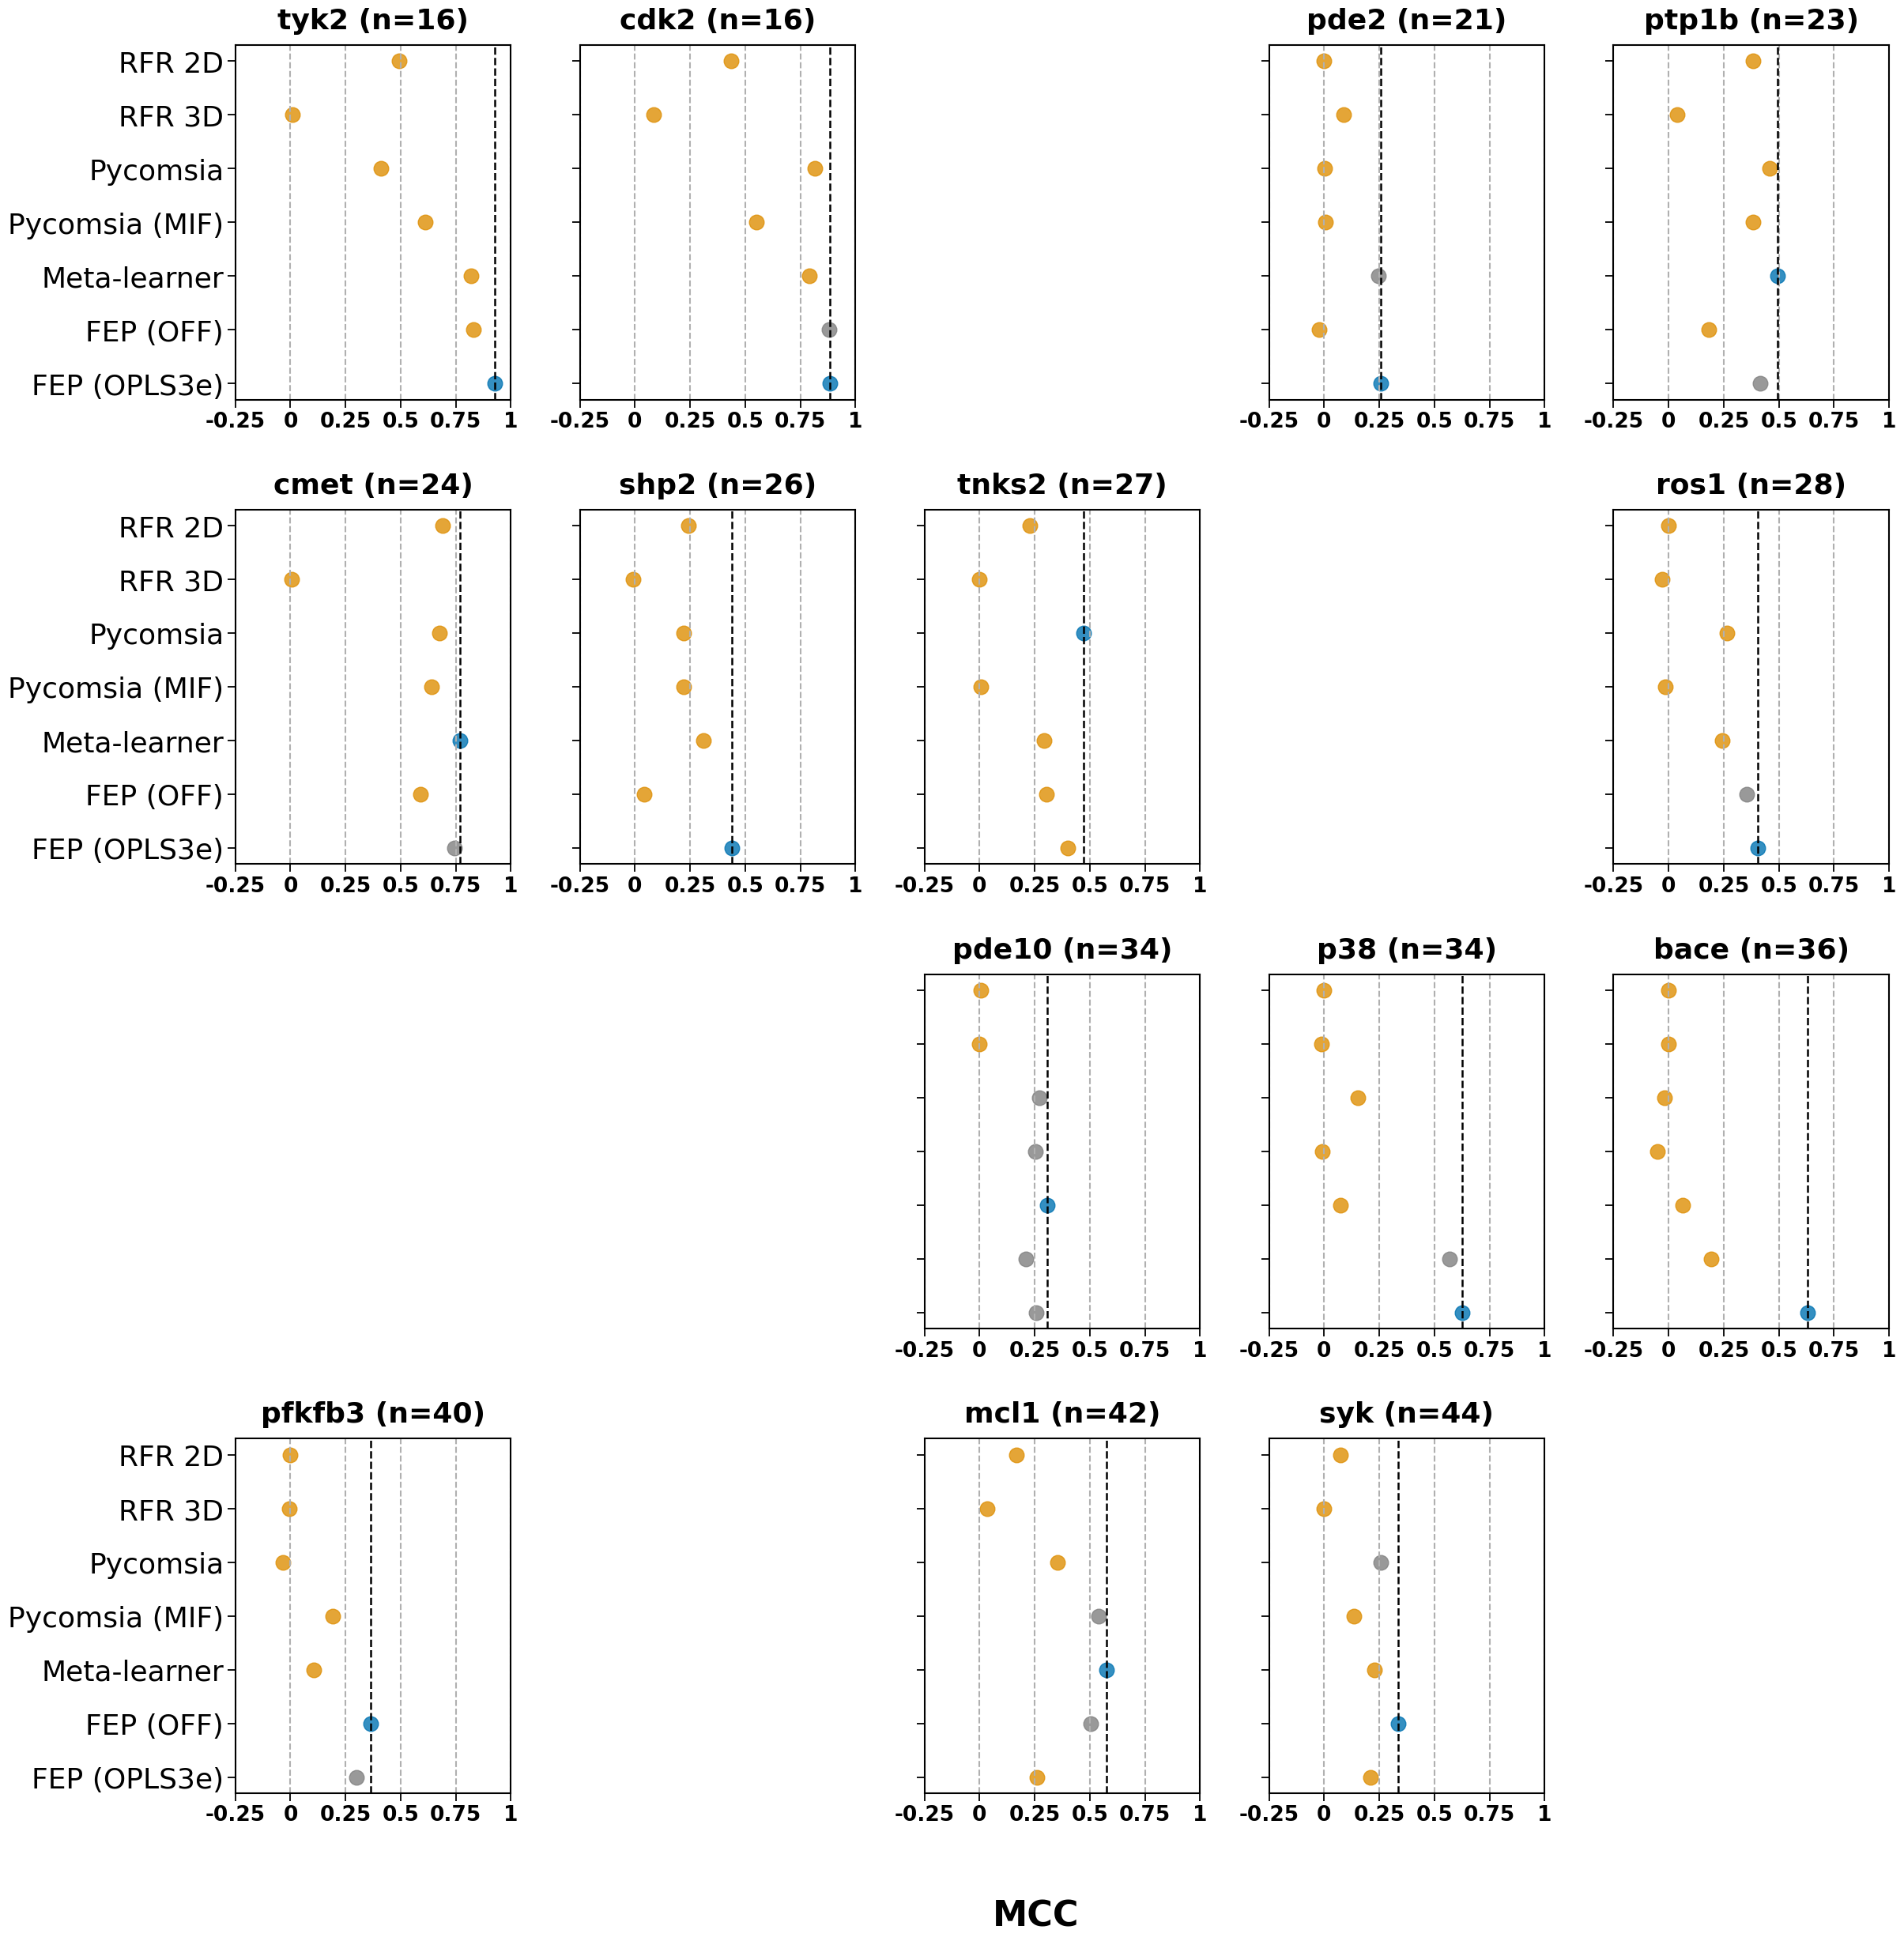


Effect-size counts for metric 'mcc':
- FEP (OFF): 2 targets → ['pfkfb3', 'syk']
- FEP (OPLS3e): 7 targets → ['tyk2', 'cdk2', 'pde2', 'shp2', 'ros1', 'p38', 'bace']
- Meta-learner: 4 targets → ['ptp1b', 'cmet', 'pde10', 'mcl1']
- Pycomsia: 1 targets → ['tnks2']
- Pycomsia (MIF): 0 targets → []
- RFR 2D: 0 targets → []
- RFR 3D: 0 targets → []


In [7]:
from DDG_ANALYSIS.E_EFFECT_SIZE_PLOT import plot_significance_ranks
plot_significance_ranks(results_all, DISPLAY_ORDER, ALPHA=ALPHA, METRICS=METRICS, target_counts_path=target_counts, COUNT_EFFECTS=True, prefix="DG_STRAT_")